# 01 · Inputs, volatility, Treasury curve and interest-rate paths

**Security:** FN FS9548 (Fannie Mae UMBS 15-year pool, 3.0% pass-through), valued as of 30 April 2026.

This notebook covers **Part I, Step 1** of the assignment: *generate a large number of interest-rate paths
at the desired frequency and horizon* (Fabozzi, Ch. on Monte Carlo valuation of MBS). It

1. loads the Bloomberg pool data and checks the derived inputs (pool factor, 32nds price conversion);
2. estimates monthly rate volatility from 10 years of month-end GT10 yields;
3. bootstraps a Treasury zero curve from the Treasury actives par curve;
4. simulates 10,000 monthly short-rate paths and calibrates their drift so that the paths reprice the
   Treasury zero curve exactly (an arbitrage-free, discrete Ho-Lee-type model).

All model code lives in `src/mbs_model.py`; the notebooks call it and show every intermediate table.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mbs_model as m
import plot_style as ps

ps.apply()
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")

## 1. Bloomberg inputs
Values transcribed from the DES / BVAL / ALLQ screens (see `data/screenshots/`).

In [2]:
inputs = m.load_inputs()
keys = ["security", "cusip", "pool_type", "coupon", "wac", "wam_months", "wala_months", "orig_amount",
        "current_balance", "factor", "payment_delay_days", "bloomberg_prepay_psa", "bval_bid_quote",
        "bval_yield", "bval_wal_years", "bloomberg_bam_toas_bp"]
pd.Series({k: inputs[k] for k in keys}, name="value").to_frame()

,value
security,FN FS9548 Mtge
cusip,3140XRTE5
pool_type,"UMBS Conventional 15-year (Super pool, FNCI 3 ..."
coupon,0.030000
wac,0.034480
wam_months,52
wala_months,125
orig_amount,5238307
current_balance,2986518
factor,0.570130


**Checks on the inputs.** The pool factor equals current / original balance, and the BVAL bid of 97-23⅝
converts to decimal as 97 + 23.625/32. BVAL quotes are *clean* prices; MBS trade with accrued interest from
the 1st of the month to settlement (29 days on a 30/360 basis for 30 April settlement).

In [3]:
mkt = m.market_prices(inputs)
checks = pd.Series({
    "factor (computed)": inputs["current_balance"] / inputs["orig_amount"],
    "factor (Bloomberg)": inputs["factor"],
    "BVAL bid (decimal)": mkt["bid"],
    "BVAL mid (decimal)": mkt["mid"],
    "accrued interest per 100": m.accrued_interest(inputs),
    "BVAL bid full price": mkt["bid"] + m.accrued_interest(inputs),
})
checks.to_frame("value")

,value
factor (computed),0.570130
factor (Bloomberg),0.570130
BVAL bid (decimal),97.738281
BVAL mid (decimal),97.769531
accrued interest per 100,0.241667
BVAL bid full price,97.979948


## 2. Monthly rate volatility from GT10 history
Month-end 10-year Treasury yields from 31 May 2016 to 30 April 2026 (120 observations, 119 monthly changes).
The Bloomberg export also contains a 5 May 2026 print; it is after the valuation date and not a month-end, so it
is excluded. Volatility is the sample standard deviation of monthly yield changes:

$$\Delta y_t = y_t - y_{t-1}, \qquad \sigma_{\text{monthly}} = \text{stdev}(\Delta y_t).$$

In [4]:
gt10 = m.load_gt10()
sigma, changes = m.estimate_monthly_vol(gt10, inputs["valuation_date"])
print(f"observations used: {len(changes) + 1} month-ends, {len(changes)} changes "
      f"({changes.index.min():%b %Y} – {changes.index.max():%b %Y})")
print(f"sigma (monthly, decimal) = {sigma:.6f}  ->  {sigma*1e4:.2f} bp per month, "
      f"{sigma*np.sqrt(12)*1e4:.1f} bp annualised")

observations used: 120 month-ends, 119 changes (Jun 2016 – Apr 2026)
sigma (monthly, decimal) = 0.002521  ->  25.21 bp per month, 87.3 bp annualised


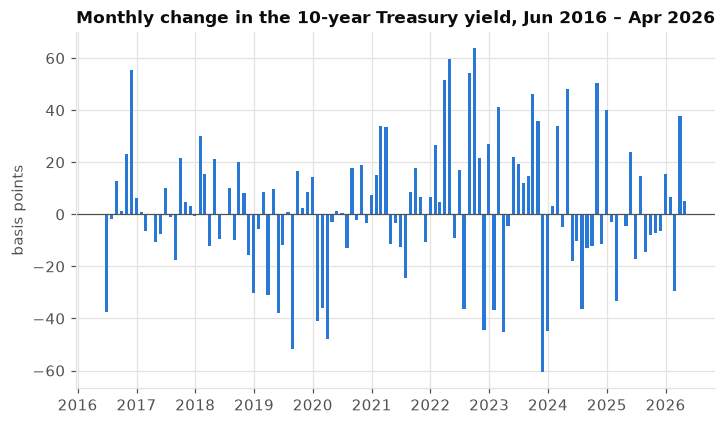

In [5]:
fig, ax = plt.subplots()
ax.bar(changes.index, changes * 1e4, width=20, color=ps.BLUE)
ax.axhline(0, color=ps.INK_2, lw=0.8)
ax.set_title("Monthly change in the 10-year Treasury yield, Jun 2016 – Apr 2026")
ax.set_ylabel("basis points")
ps.save(fig, "01_gt10_monthly_changes")

## 3. Treasury zero curve
The Treasury actives curve gives par yields (semiannual bond-equivalent). Bills (3m, 6m, 1y) are treated as
zero-coupon yields; from 1.5 to 5 years the par yield is linearly interpolated and discount factors are
bootstrapped from the par-bond condition

$$1 = \frac{y_n}{2}\sum_{k<n} P(t_k) + \left(1 + \frac{y_n}{2}\right) P(t_n).$$

Monthly discount factors $P(0, t/12)$ are then obtained by linear interpolation of continuously compounded zero
rates. The horizon needed is 52 months (≈ 4.3 years).

In [6]:
zero = m.bootstrap_zero_curve(inputs["treasury_par_curve"])
zero

,years,par_yield,discount_factor,zero_cc,zero_bey
0,0.250000,0.036550,0.990986,0.036220,0.036550
1,0.500000,0.036730,0.981966,0.036397,0.036730
2,1.000000,0.037040,0.963964,0.036701,0.037040
3,1.500000,0.037935,0.945163,0.037598,0.037954
4,2.000000,0.038830,0.925893,0.038498,0.038871
5,2.500000,0.039060,0.907726,0.038725,0.039102
6,3.000000,0.039290,0.889705,0.038955,0.039337
7,3.500000,0.039520,0.871832,0.039188,0.039575
8,4.000000,0.039750,0.854110,0.039424,0.039815
9,4.500000,0.039980,0.836544,0.039661,0.040057


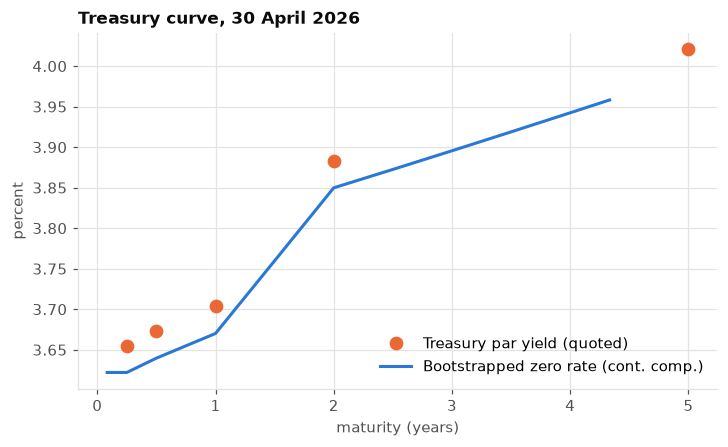

In [7]:
T = inputs["wam_months"]
P = m.monthly_discount_factors(zero, T)
months = np.arange(T + 1)
fig, ax = plt.subplots()
par = pd.Series(inputs["treasury_par_curve"]).rename(index=float).sort_index()
par = par[par.index <= 5]
ax.plot(par.index, par.values * 100, "o", color=ps.ORANGE, ms=8, label="Treasury par yield (quoted)")
z_m = -np.log(P[1:]) / (months[1:] / 12)
ax.plot(months[1:] / 12, z_m * 100, color=ps.BLUE, label="Bootstrapped zero rate (cont. comp.)")
ax.set_xlabel("maturity (years)")
ax.set_ylabel("percent")
ax.set_title("Treasury curve, 30 April 2026")
ax.legend(loc="lower right")
ps.save(fig, "02_treasury_curve")

## 4. Interest-rate paths
**Model.** Let $r_k$ be the annualised one-month Treasury rate for month $k \to k+1$ (monthly compounding).

$$r_k^{(i)} = \max\!\left(0,\ \theta_k + \sigma W_k^{(i)}\right), \qquad W_k^{(i)} = \sum_{j=1}^{k}\varepsilon_j^{(i)},\quad \varepsilon \sim N(0,1)$$

* $r_0$ is the one-month rate implied by the zero curve: $r_0 = 12\,[P(0,0)/P(0,1) - 1]$.
* $\theta_k$ is solved month by month so that the **average path discount factor equals the Treasury discount
  factor**: $\frac{1}{N}\sum_i \prod_{j=0}^{k} (1+r_j^{(i)}/12)^{-1} = P(0, k+1)$. This removes the arbitrage
  that arises when paths are simply started at today's rate with no drift, and is the discrete analogue of the
  calibration Fabozzi describes (paths adjusted so the model values Treasuries correctly).
* 10,000 paths = 5,000 antithetic pairs ($\varepsilon$ and $-\varepsilon$), fixed seed 2026, so every number
  in the project is exactly reproducible and every scenario is valued on the **same** paths.
* $\sigma W_k$ is also used as the simulated change in long-term (mortgage) rates that drives refinancing in
  notebook 02. That is consistent with $\sigma$ being estimated from 10-year yield changes.

In [8]:
case = m.build_base_case()
paths = case["paths"]
D = m.path_discount_factors(paths.rates)
calib = pd.DataFrame({
    "month": months[1:],
    "Treasury P(0,t)": paths.market_df[1:],
    "mean path DF": D.mean(axis=0),
    "theta_t": paths.theta,
})
calib["abs error"] = (calib["Treasury P(0,t)"] - calib["mean path DF"]).abs()
print(f"max calibration error: {calib['abs error'].max():.2e}")
print(f"share of path-months at the zero floor: {(paths.rates == 0).mean():.3%}")
calib.iloc[[0, 1, 2, 11, 23, 35, 47, 51]]

max calibration error: 1.33e-13
share of path-months at the zero floor: 0.182%


,month,"Treasury P(0,t)",mean path DF,theta_t,abs error
0,1,0.996986,0.996986,0.036275,0.000000
1,2,0.993982,0.993982,0.036275,0.000000
2,3,0.990986,0.990986,0.036276,0.000000
11,12,0.963964,0.963964,0.037352,0.000000
23,24,0.925893,0.925893,0.042162,0.000000
35,36,0.889705,0.889705,0.040677,0.000000
47,48,0.854110,0.854110,0.041870,0.000000
51,52,0.842381,0.842381,0.042291,0.000000


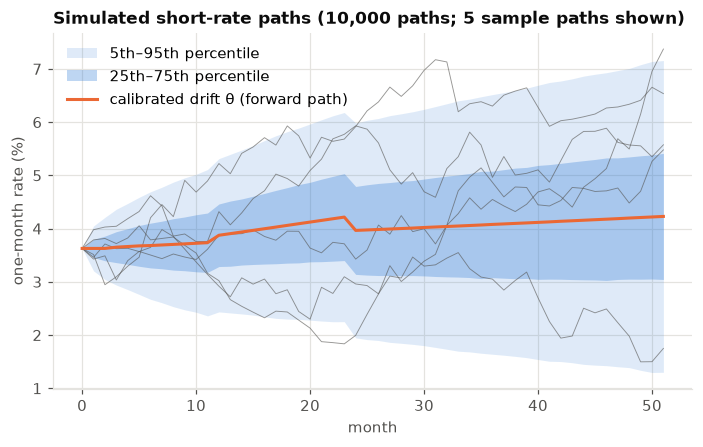

In [9]:
pct = np.percentile(paths.rates * 100, [5, 25, 50, 75, 95], axis=0)
fig, ax = plt.subplots()
x = months[:-1]
ax.fill_between(x, pct[0], pct[4], color=ps.BLUE, alpha=0.15, lw=0, label="5th–95th percentile")
ax.fill_between(x, pct[1], pct[3], color=ps.BLUE, alpha=0.30, lw=0, label="25th–75th percentile")
for i in range(5):
    ax.plot(x, paths.rates[i] * 100, color=ps.INK_2, lw=0.6, alpha=0.6)
ax.plot(x, paths.theta * 100, color=ps.ORANGE, label="calibrated drift θ (forward path)")
ax.set_xlabel("month")
ax.set_ylabel("one-month rate (%)")
ax.set_title("Simulated short-rate paths (10,000 paths; 5 sample paths shown)")
ax.legend(loc="upper left")
ps.save(fig, "03_rate_paths")

### First path in detail
This is the path that the Excel workbook (`excel/FN_FS9548_MBS_Pricing_Model.xlsx`, sheet *Rate Paths*)
rebuilds with formulas from the same shocks.

In [10]:
eps_k = np.concatenate([[0.0], paths.eps[0, : T - 1]])   # ε_k enters W_k; no shock at k = 0
p1 = pd.DataFrame({"month": x, "shock ε_k": eps_k, "θ_k": paths.theta,
                   "σW_k": paths.shock[0], "r_k": paths.rates[0]})
p1.head(12)

,month,shock ε_k,θ_k,σW_k,r_k
0,0,0.000000,0.036275,0.000000,0.036275
1,1,-0.793122,0.036275,-0.001999,0.034276
2,2,0.240571,0.036276,-0.001393,0.034884
3,3,-1.896326,0.036514,-0.006173,0.030342
4,4,1.395772,0.036634,-0.002654,0.033980
5,5,0.638295,0.036755,-0.001046,0.035710
6,6,-0.292047,0.036819,-0.001782,0.035037
7,7,-0.311949,0.036924,-0.002568,0.034357
8,8,0.303835,0.037030,-0.001802,0.035228
9,9,-0.267660,0.037137,-0.002477,0.034660
